# KLAR 已保存 500 样本：AWQ-INT4 错误子集的五组神经元恢复

只复用已保存的 FP16/GPTQ baseline，不重新生成基线。严格读取 notebook 11 导出的 FP16 Wikipedia LAPE 索引；若 notebook 11 的 CSV 已覆盖全部 12 个目标语言，就直接使用；否则复用 notebook 11 保存的六语言 FP16 Wikipedia 激活统计，补算缺失语言的同口径统计，并在 13 种语言上重新识别 LAPE。目标语言全部 12 种均参与 recovery。

执行本 notebook 即可：前面单元负责加载模型工具、旧 Transfer 分数与原 500 样本清单；最后仅对 **FP16 正确且 AWQ-INT4 错误**的样本运行 LAPE、Transfer、两者联合、全语言联合及等量随机五组恢复。恢复方式沿用本 notebook 的 FP16-minus-GPTQ down-projection contribution 替换。新结果写入独立目录，原始 baseline/recovery CSV 不覆盖。

AWQ 的量化 baseline 从既有的全部对齐事实 CSV 中按同一 500 个 sample_id 提取；不重跑 AWQ 或 FP16 baseline。


**Method references and attribution.** LAPE neuron identification is based on [Tang et al. (ACL 2024), *Language-Specific Neurons: The Key to Multilingual Capabilities in Large Language Models*](https://aclanthology.org/2024.acl-long.309/). The notebook reuses the project's FP16 Wikipedia LAPE indices and applies the stated thresholds and recovery masks in a quantization study. The five recovery groups, cross-language pooling, and AWQ/GPTQ/BNB contribution-replacement comparisons are project-specific extensions; they should not be attributed to the original LAPE paper.


In [1]:
import csv, gc, hashlib, json, math, os, random, urllib.parse, urllib.request, warnings, zipfile
from collections import Counter, defaultdict
from pathlib import Path

os.environ.setdefault('HF_ENDPOINT', 'https://hf-mirror.com')
os.environ.setdefault('HF_HOME', '/root/autodl-tmp/huggingface')
os.environ.setdefault('HF_DATASETS_CACHE', '/root/autodl-tmp/huggingface/datasets')
os.environ.setdefault('HF_HUB_DISABLE_XET', '1')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

torch.set_grad_enabled(False)

# Faster matrix multiplication for the very large score GEMMs on Ampere+ GPUs.
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True
torch.set_float32_matmul_precision('high')


libgomp: Invalid value for environment variable OMP_NUM_THREADS


## 1. 配置

In [2]:
FP16_CHECKPOINT = Path('/root/autodl-tmp/models/llama3.1-8b/llama3.1-8b-instruct')
QUANT_SPECS = {
    'GPTQ-INT4': {
        'kind': 'checkpoint',
        'checkpoint': Path('/root/autodl-tmp/models/llama3.1-8b/llama3.1-8b-gptq-int4'),
    },
}
QUANT_SPECS['AWQ-INT4'] = {'kind': 'checkpoint', 'checkpoint': Path('/root/autodl-tmp/models/llama3.1-8b/llama3.1-8b-awq-int4')}
QUANT_MODEL_NAME = 'AWQ-INT4'
ACTIVE_QUANT_METHODS = [QUANT_MODEL_NAME]
LANGUAGES = ['ca', 'en', 'es', 'fr', 'hu', 'nl', 'tr', 'ar', 'el', 'he', 'ja', 'ko', 'zh']
TARGET_LANGUAGES = [language for language in LANGUAGES if language != 'en']
LANGUAGE_SCRIPT_GROUPS = {
    'ca': 'Latin', 'es': 'Latin', 'fr': 'Latin', 'hu': 'Latin',
    'nl': 'Latin', 'tr': 'Latin', 'ar': 'Non-Latin', 'el': 'Non-Latin',
    'he': 'Non-Latin', 'ja': 'Non-Latin', 'ko': 'Non-Latin', 'zh': 'Non-Latin',
}
DATASET_TAG = 'paper_tatoeba_1000_12targets_latin_nonlatin'
SCORE_DIR = (Path('/root/autodl-tmp/analysis') /
             f'type1_bridge_neuron_stats_{DATASET_TAG}' /
             'last_nonpadding_token')
FP_SCORE_PATH = SCORE_DIR / 'paper_scores_fp16_layers_0_7_last_token_fp32_score.pt'
KLAR_DATA_DIR = Path('/root/autodl-tmp/data/klar')
KLAR_OUTPUT_DIR = Path('/root/autodl-tmp/analysis') / 'klar_gptq_english_500facts_template0_12languages_top1_fp16'
KLAR_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FP16_BASELINE_DIR = KLAR_OUTPUT_DIR
QUANT_BASELINE_DIR = Path('/root/autodl-tmp/analysis') / 'klar_awq_all_aligned_facts_template0_12languages_top1_fp16'
QUANT_BASELINE_DIR.mkdir(parents=True, exist_ok=True)
LAPE_JOINT_OUTPUT_DIR = QUANT_BASELINE_DIR / 'notebook11_lape_transfer_five_conditions_all12_eligible_only'
LAPE_JOINT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
LAPE_CACHE_DIR = Path('/root/autodl-tmp/analysis') / 'paper_wikipedia_lape_13languages_fp16_cache'
LAPE_CACHE_DIR.mkdir(parents=True, exist_ok=True)
LAPE_FULL_INDEX_PATH = LAPE_CACHE_DIR / 'wikipedia_lape_selected_neuron_indices_13languages.csv'
LAPE_OLD_DIR = Path('/root/autodl-tmp/analysis') / 'paper_wikipedia_lape_quantization'
WIKI_LOCAL_ROOT = Path('/root/autodl-tmp/data/wikipedia')
WIKI_DATASET_NAME = 'wikimedia/wikipedia'
WIKI_CONFIG_DATE = '20231101'
WIKI_DISCOVERY_TOKENS_PER_LANGUAGE = 1_000_000
WIKI_SEQUENCE_LENGTH = 512
WIKI_STATS_BATCH_SIZE = 4
LAPE_BOTTOM_RATE = 0.10
LAPE_ACTIVITY_QUANTILE = 0.95
LAPE_INDEX_PATH = (Path('/root/autodl-tmp/analysis') /
                   'paper_wikipedia_lape_quantization' /
                   'layers0_7_full_answer_recovery_gpu_gptq' /
                   'wikipedia_lape_selected_neuron_indices.csv')

SEED = 2026
DTYPE = torch.float16
DEVICE_MAP = 'auto'
TRUST_REMOTE_CODE = True
RECOVERY_LAYERS = list(range(8))
CANDIDATE_LAYERS = RECOVERY_LAYERS.copy()
TOP_RATE = 0.01
KLAR_N_SHOT = 5
KLAR_ADD_GENERATION_PROMPT = True
KLAR_MAX_LENGTH = 1024
KLAR_GENERATION_MAX_NEW_TOKENS = 8
KLAR_Q_FORWARD_BATCH_SIZE = 16
KLAR_GENERATION_CONDITIONS_PER_BATCH = 4
RECOVERY_CONDITION_NAMES = [
    'lape', 'transfer', 'lape_plus_transfer',
    'all_language_lape_plus_transfer', 'random_largest_matched',
]
KLAR_SAMPLE_TOTAL = 500  # 500 aligned English facts, paired across all target languages
KLAR_SAMPLE_SEED = SEED + 50500
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print(QUANT_MODEL_NAME, 'languages:', TARGET_LANGUAGES)
print('Output:', KLAR_OUTPUT_DIR)


AWQ-INT4 languages: ['ca', 'es', 'fr', 'hu', 'nl', 'tr', 'ar', 'el', 'he', 'ja', 'ko', 'zh']
Output: /root/autodl-tmp/analysis/klar_gptq_english_500facts_template0_12languages_top1_fp16


## 2. 模型与 AWQ-INT4 权重工具

In [3]:
def decoder_layers(model):
    for path in ('model.layers', 'model.decoder.layers', 'transformer.h', 'gpt_neox.layers'):
        obj = model
        ok = True
        for part in path.split('.'):
            if not hasattr(obj, part):
                ok = False
                break
            obj = getattr(obj, part)
        if ok:
            return obj
    raise AttributeError('Decoder layers not found.')

def input_device(model):
    return model.get_input_embeddings().weight.device

def load_tokenizer():
    tok = AutoTokenizer.from_pretrained(FP16_CHECKPOINT, trust_remote_code=TRUST_REMOTE_CODE)
    tok.padding_side = 'right'
    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token
    return tok

def load_model(name):
    if name == 'FP16':
        checkpoint = FP16_CHECKPOINT
        kwargs = {'torch_dtype': DTYPE}
    else:
        spec = QUANT_SPECS[name]
        checkpoint = Path(spec['checkpoint'])
        if spec['kind'] == 'bnb_nf4':
            kwargs = {'quantization_config': BitsAndBytesConfig(
                load_in_4bit=True,
                bnb_4bit_quant_type='nf4',
                bnb_4bit_compute_dtype=DTYPE,
            )}
        else:
            kwargs = {'torch_dtype': DTYPE}
    if not Path(checkpoint).exists():
        raise FileNotFoundError(f'Missing checkpoint: {checkpoint}')
    model = AutoModelForCausalLM.from_pretrained(
        checkpoint,
        device_map=({'': 0} if name in {'AWQ-INT4', 'BNB-NF4'} else DEVICE_MAP),
        low_cpu_mem_usage=True,
        trust_remote_code=TRUST_REMOTE_CODE,
        **kwargs,
    ).eval()
    model.config.use_cache = False
    return model

def encode_batch(tokenizer, texts, device):
    batch = tokenizer(
        texts,
        return_tensors='pt',
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        add_special_tokens=True,
    )
    return {k: v.to(device) for k, v in batch.items()}

def last_token_pool(sequence, attention_mask):
    """Select the last non-padding token for each sentence in a padded batch."""
    if (~attention_mask.bool().any(dim=1)).any():
        raise ValueError('At least one sequence contains no valid tokens.')
    if sequence.shape[:2] != attention_mask.shape:
        raise ValueError('Hidden-state sequence and attention mask must align.')
    positions = attention_mask.shape[1] - 1 - attention_mask.flip(1).long().argmax(dim=1)
    rows = torch.arange(sequence.shape[0], device=sequence.device)
    return sequence[rows, positions.to(sequence.device)]


def orient_weight(candidate, module):
    out_features, in_features = int(module.out_features), int(module.in_features)
    candidate = candidate.detach()
    if tuple(candidate.shape) == (out_features, in_features):
        return candidate
    if tuple(candidate.shape) == (in_features, out_features):
        return candidate.t().contiguous()
    raise ValueError(
        f'Cannot orient {module.__class__.__name__} weight {tuple(candidate.shape)} '
        f'as {(out_features, in_features)}.'
    )

def manual_gptq_dequantize(module):
    bits = int(module.bits)
    maxq = (1 << bits) - 1
    pack = 32 // bits
    qweight = module.qweight.to(torch.int64)
    shifts = torch.arange(0, 32, bits, device=qweight.device, dtype=torch.int64)
    unpacked = ((qweight.unsqueeze(1) >> shifts.view(1, pack, 1)) & maxq)
    unpacked = unpacked.reshape(-1, qweight.shape[-1])[:module.in_features]
    qzeros = module.qzeros.to(torch.int64)
    zeros = ((qzeros.unsqueeze(-1) >> shifts.view(1, 1, pack)) & maxq)
    zeros = zeros.reshape(qzeros.shape[0], -1)[:, :module.out_features] + 1
    scales = module.scales.float()
    g_idx = module.g_idx.long() if hasattr(module, 'g_idx') else (
        torch.arange(module.in_features, device=qweight.device) // int(module.group_size)
    )
    weight_in_out = (unpacked.float() - zeros[g_idx].float()) * scales[g_idx]
    return weight_in_out.t().contiguous()


_SAFETENSOR_INDEX_CACHE = {}

def safetensor_weight_map(checkpoint):
    checkpoint = Path(checkpoint)
    key = str(checkpoint.resolve())
    if key in _SAFETENSOR_INDEX_CACHE:
        return _SAFETENSOR_INDEX_CACHE[key]
    index_path = checkpoint / 'model.safetensors.index.json'
    if index_path.exists():
        mapping = json.loads(index_path.read_text())['weight_map']
    else:
        from safetensors import safe_open
        mapping = {}
        for shard in checkpoint.glob('*.safetensors'):
            with safe_open(shard, framework='pt', device='cpu') as handle:
                for tensor_key in handle.keys():
                    mapping[tensor_key] = shard.name
    if not mapping:
        raise FileNotFoundError(f'No safetensors found in {checkpoint}.')
    _SAFETENSOR_INDEX_CACHE[key] = mapping
    return mapping

def load_checkpoint_tensor(checkpoint, suffix, required=True):
    from safetensors import safe_open
    checkpoint = Path(checkpoint)
    mapping = safetensor_weight_map(checkpoint)
    matches = [key for key in mapping if key.endswith(suffix)]
    if len(matches) != 1:
        if required:
            raise KeyError(f'Expected one tensor ending in {suffix!r}; found {matches[:5]}')
        return None
    tensor_key = matches[0]
    with safe_open(checkpoint / mapping[tensor_key], framework='pt', device='cpu') as handle:
        return handle.get_tensor(tensor_key)

def dequantize_gptq_checkpoint(qweight, qzeros, scales, g_idx,
                               in_features, out_features, bits, group_size):
    maxq = (1 << bits) - 1
    pack = 32 // bits
    shifts = torch.arange(0, 32, bits, dtype=torch.int64)
    qweight = qweight.to(torch.int64)
    if qweight.shape[1] == out_features:
        unpacked = ((qweight.unsqueeze(1) >> shifts.view(1, pack, 1)) & maxq)
        unpacked = unpacked.reshape(-1, out_features)[:in_features]
    elif qweight.shape[0] == in_features and qweight.shape[1] * pack >= out_features:
        unpacked = ((qweight.unsqueeze(-1) >> shifts.view(1, 1, pack)) & maxq)
        unpacked = unpacked.reshape(in_features, -1)[:, :out_features]
    else:
        raise RuntimeError(
            f'Unsupported serialized GPTQ layout {tuple(qweight.shape)} for '
            f'in={in_features}, out={out_features}.'
        )
    qzeros = qzeros.to(torch.int64)
    zeros = ((qzeros.unsqueeze(-1) >> shifts.view(1, 1, pack)) & maxq)
    zeros = zeros.reshape(qzeros.shape[0], -1)[:, :out_features] + 1
    scales = scales.float().reshape(scales.shape[0], out_features)
    if g_idx is None:
        g_idx = torch.arange(in_features) // group_size
    g_idx = g_idx.long()[:in_features]
    return ((unpacked.float() - zeros[g_idx].float()) * scales[g_idx]).t().contiguous()

@torch.no_grad()
def serialized_gptq_down_weight(layer_index, reference_module):
    checkpoint = Path(QUANT_SPECS['GPTQ-INT4']['checkpoint'])
    suffix = f'layers.{layer_index}.mlp.down_proj.'
    qweight = load_checkpoint_tensor(checkpoint, suffix + 'qweight')
    qzeros = load_checkpoint_tensor(checkpoint, suffix + 'qzeros')
    scales = load_checkpoint_tensor(checkpoint, suffix + 'scales')
    g_idx = load_checkpoint_tensor(checkpoint, suffix + 'g_idx', required=False)
    config = json.loads((checkpoint / 'config.json').read_text())
    qconfig = config.get('quantization_config', {})
    bits = int(qconfig.get('bits', 4))
    group_size = int(qconfig.get('group_size', 128))
    dense = dequantize_gptq_checkpoint(
        qweight, qzeros, scales, g_idx,
        int(reference_module.in_features), int(reference_module.out_features),
        bits, group_size,
    )
    return orient_weight(dense, reference_module)

@torch.no_grad()
def dense_linear_weight(module):
    class_name = module.__class__.__name__.lower()
    weight = getattr(module, 'weight', None)
    if weight is not None and weight.__class__.__name__ == 'Params4bit':
        import bitsandbytes as bnb
        candidate = bnb.functional.dequantize_4bit(weight.data, weight.quant_state)
    elif hasattr(module, 'dequantize_weight'):
        try:
            candidate = module.dequantize_weight()
        except Exception:
            if hasattr(module, 'qweight') and hasattr(module, 'qzeros') and hasattr(module, 'scales'):
                candidate = manual_gptq_dequantize(module)
            else:
                raise
    elif 'awq' in class_name or ('wqlinear' in class_name and hasattr(module, 'qzeros')):
        from awq.utils.packing_utils import dequantize_gemm
        candidate = dequantize_gemm(
            module.qweight, module.qzeros, module.scales,
            int(module.w_bit), int(module.group_size),
        )
    elif hasattr(module, 'qweight') and hasattr(module, 'qzeros') and hasattr(module, 'scales'):
        candidate = manual_gptq_dequantize(module)
    elif weight is not None and weight.ndim == 2 and weight.is_floating_point():
        candidate = weight
    else:
        raise TypeError(
            f'Unsupported linear module: {module.__class__.__module__}.{module.__class__.__name__}'
        )
    return orient_weight(candidate, module).detach()

@torch.no_grad()
def bridge_down_weight(model_name, layer_index, module):
    # Loaded GPTQ modules may be converted to Marlin layout (e.g. 8192×4096),
    # so bridge analysis reads and dequantizes the original checkpoint tensors.
    if model_name == 'GPTQ-INT4':
        return serialized_gptq_down_weight(layer_index, module)
    return dense_linear_weight(module)

TOKENIZER = load_tokenizer()

## 3. 读取已有 FP16 原论文分数并确定神经元

In [4]:
score_payload = torch.load(FP_SCORE_PATH, map_location='cpu', weights_only=False)
if score_payload.get('token_representation') != 'last_nonpadding_token':
    raise RuntimeError('Expected last-token FP16 discovery scores.')
if score_payload.get('candidate_layers') != RECOVERY_LAYERS:
    raise RuntimeError('FP16 score cache must cover exactly decoder layers 0–7.')
FP_PAPER_SCORES = score_payload['paper_scores']
for language in TARGET_LANGUAGES:
    if language not in FP_PAPER_SCORES:
        raise KeyError(f'Missing FP16 paper scores for {language}')
shape = tuple(FP_PAPER_SCORES[TARGET_LANGUAGES[0]].shape)
if len(shape) != 2 or shape[0] != len(RECOVERY_LAYERS):
    raise RuntimeError(f'Unexpected FP16 score shape: {shape}')
INTERMEDIATE_SIZE = shape[1]
for language in TARGET_LANGUAGES:
    if tuple(FP_PAPER_SCORES[language].shape) != shape:
        raise RuntimeError(f'Inconsistent score shape for {language}')

# One shared threshold over all language × layer × neuron scores. Counts per
# language are therefore allowed to differ; ties at the cutoff are retained.
pooled_scores = torch.cat([
    FP_PAPER_SCORES[language].float().reshape(-1)
    for language in TARGET_LANGUAGES
])
if not bool(torch.isfinite(pooled_scores).all()):
    raise RuntimeError('FP16 score cache has non-finite values.')
top_count = math.ceil(pooled_scores.numel() * TOP_RATE)
FP_TOP1_THRESHOLD = float(torch.topk(
    pooled_scores, k=top_count, largest=True, sorted=False
).values.min())
TOP1_MASKS = {
    language: FP_PAPER_SCORES[language].float() >= FP_TOP1_THRESHOLD
    for language in TARGET_LANGUAGES
}
PAPER_MASKS = {
    language: {
        layer: torch.nonzero(
            TOP1_MASKS[language][layer], as_tuple=False
        ).squeeze(1).cpu().long()
        for layer in RECOVERY_LAYERS
    }
    for language in TARGET_LANGUAGES
}
ALL_LANGUAGE_UNION = {
    layer: torch.unique(torch.cat([
        PAPER_MASKS[language][layer] for language in TARGET_LANGUAGES
    ])).sort().values
    for layer in RECOVERY_LAYERS
}
RANDOM_ELIGIBLE_BY_LAYER = {
    layer: np.setdiff1d(
        np.arange(INTERMEDIATE_SIZE, dtype=np.int64),
        ALL_LANGUAGE_UNION[layer].numpy(), assume_unique=True,
    )
    for layer in RECOVERY_LAYERS
}
union_rng = np.random.default_rng(SEED + 77117)
RANDOM_UNION = {}
for layer in RECOVERY_LAYERS:
    count = len(ALL_LANGUAGE_UNION[layer])
    pool = RANDOM_ELIGIBLE_BY_LAYER[layer]
    if count > len(pool):
        raise RuntimeError(f'Layer {layer}: too few non-transfer neurons for union control.')
    RANDOM_UNION[layer] = torch.as_tensor(
        union_rng.choice(pool, size=count, replace=False).copy(), dtype=torch.long,
    )

RECOVERY_MASKS = {'GPTQ-INT4': {}}
id_rows, count_rows = [], []
for language_index, language in enumerate(TARGET_LANGUAGES):
    rng = np.random.default_rng(SEED + 10103 * language_index)
    random_local = {}
    for layer in RECOVERY_LAYERS:
        count = len(PAPER_MASKS[language][layer])
        pool = RANDOM_ELIGIBLE_BY_LAYER[layer]
        if count > len(pool):
            raise RuntimeError(f'{language}/layer {layer}: random pool too small.')
        random_local[layer] = torch.as_tensor(
            rng.choice(pool, size=count, replace=False).copy(), dtype=torch.long,
        )
    RECOVERY_MASKS['GPTQ-INT4'][language] = {
        'language_top1': PAPER_MASKS[language],
        'random_language_matched': random_local,
        'all_languages_top1_union': ALL_LANGUAGE_UNION,
        'random_union_matched': RANDOM_UNION,
    }
    for condition, by_layer in RECOVERY_MASKS['GPTQ-INT4'][language].items():
        for layer in RECOVERY_LAYERS:
            for neuron in by_layer[layer].tolist():
                id_rows.append({
                    'language': language, 'condition': condition,
                    'layer': layer, 'neuron_index': int(neuron),
                })
        count_rows.append({
            'language': language, 'condition': condition,
            'neurons': sum(len(by_layer[layer]) for layer in RECOVERY_LAYERS),
        })
    for transfer, control in (
        ('language_top1', 'random_language_matched'),
        ('all_languages_top1_union', 'random_union_matched'),
    ):
        for layer in RECOVERY_LAYERS:
            left = RECOVERY_MASKS['GPTQ-INT4'][language][transfer][layer]
            right = RECOVERY_MASKS['GPTQ-INT4'][language][control][layer]
            assert len(left) == len(right)
            assert not bool(np.intersect1d(
                right.numpy(), ALL_LANGUAGE_UNION[layer].numpy()
            ).size)

pd.DataFrame(id_rows).to_csv(KLAR_OUTPUT_DIR / 'selected_neuron_ids.csv', index=False)
selection_count_df = pd.DataFrame(count_rows)
selection_count_df.to_csv(KLAR_OUTPUT_DIR / 'selected_neuron_counts.csv', index=False)
print('FP16 pooled Top-1% cutoff:', FP_TOP1_THRESHOLD)
display(selection_count_df.pivot(index='language', columns='condition', values='neurons'))


FP16 pooled Top-1% cutoff: 0.00019244213763158768


condition,all_languages_top1_union,language_top1,random_language_matched,random_union_matched
language,,,,
ar,3143,1119,1119,3143
ca,3143,1045,1045,3143
el,3143,1120,1120,3143
es,3143,965,965,3143
fr,3143,1015,1015,3143
he,3143,1271,1271,3143
hu,3143,1165,1165,3143
ja,3143,1557,1557,3143
ko,3143,1163,1163,3143


## 4. 从跨语言对齐事实中随机抽取 500 条，并使用原实验 5-shot prompt

In [5]:
def load_klar_language(language):
    path = KLAR_DATA_DIR / f'{language}.json'
    if not path.is_file():
        raise FileNotFoundError(f'Missing KLAR file: {path}')
    raw = json.loads(path.read_text(encoding='utf-8'))
    flattened = []
    for relation_index, relation in enumerate(raw):
        relation_name = relation.get('relation_name', f'relation_{relation_index}')
        templates = relation['prompt_templates']
        for sample in relation['samples']:
            variants = []
            for template_id, template in enumerate(templates):
                variants.append({
                    'question': template.replace('<subject>', sample['subject']).split('<mask>')[0],
                    'answer': sample['object'],
                    'index': sample['index'],
                    'relation_name': relation_name,
                    'relation_id': relation.get('relation_id', ''),
                    'subject_en': sample['subject'] if language == 'en'
                                  else sample.get('subject_en', ''),
                    'object_en': sample['object'] if language == 'en'
                                 else sample.get('object_en', ''),
                    'template_id': template_id,
                })
            flattened.append(variants)
    if len(flattened) <= KLAR_N_SHOT:
        raise ValueError(f'{language}: fewer than {KLAR_N_SHOT + 1} facts')
    demonstrations = [flattened[i][i] for i in range(KLAR_N_SHOT)]
    return demonstrations, flattened[KLAR_N_SHOT:]

KLAR_RAW = {language: load_klar_language(language)
            for language in LANGUAGES}
def klar_prompt_messages(language, record_id, template_id):
    demonstrations, evaluation = KLAR_RAW[language]
    messages = []
    for demonstration in demonstrations:
        messages.extend([
            {'role': 'user', 'content': demonstration['question']},
            {'role': 'assistant', 'content': demonstration['answer']},
        ])
    current = evaluation[int(record_id)][int(template_id)]
    messages.append({'role': 'user', 'content': current['question']})
    return messages

def klar_prompt_text(language, record_id, template_id):
    return TOKENIZER.apply_chat_template(
        klar_prompt_messages(language, record_id, template_id),
        tokenize=False, add_generation_prompt=KLAR_ADD_GENERATION_PROMPT,
    )

def normalize_answer_for_match(text):
    import unicodedata
    value = unicodedata.normalize('NFKC', str(text))
    value = ' '.join(value.strip().split()).casefold()
    return value.strip(' \t\n\r.,;:!?。；：！？"\'`“”‘’()[]{}')

def answer_contains_gold(prediction, gold_answer):
    gold = normalize_answer_for_match(gold_answer)
    return bool(gold) and gold in normalize_answer_for_match(prediction)

_, english_evaluation = KLAR_RAW['en']
target_evaluations = {
    language: KLAR_RAW[language][1] for language in TARGET_LANGUAGES
}
for language, evaluation in target_evaluations.items():
    if len(evaluation) != len(english_evaluation):
        raise RuntimeError(
            f'{language}: {len(evaluation)} facts vs English '
            f'{len(english_evaluation)}; position-based pairing is unsafe.'
        )

def aligned_fact(record_id):
    english_variants = english_evaluation[record_id]
    if not english_variants:
        return False, 'English has no template'
    english = english_variants[0]
    for language, evaluation in target_evaluations.items():
        target_variants = evaluation[record_id]
        if not target_variants:
            return False, f'{language}: no template'
        target = target_variants[0]
        for field in ('index', 'relation_id'):
            if str(target[field]) != str(english[field]):
                return False, f'{language}: {field} mismatch'
        for field in ('subject_en', 'object_en'):
            if target[field] and str(target[field]).strip().casefold() != (
                str(english[field]).strip().casefold()
            ):
                return False, f'{language}: {field} mismatch'
    return True, ''

eligible_record_ids = []
excluded_reasons = Counter()
for record_id in range(len(english_evaluation)):
    valid, reason = aligned_fact(record_id)
    if valid:
        eligible_record_ids.append(record_id)
    else:
        excluded_reasons[reason] += 1
print('English facts eligible across all target languages:',
      len(eligible_record_ids), '/', len(english_evaluation))
if excluded_reasons:
    print('Excluded alignment reasons:', excluded_reasons.most_common(10))
if len(eligible_record_ids) < KLAR_SAMPLE_TOTAL:
    raise ValueError(
        f'Only {len(eligible_record_ids)} facts align across all target languages; '
        f'need {KLAR_SAMPLE_TOTAL}.'
    )
sample_manifest_path = KLAR_OUTPUT_DIR / 'sampled_english_500_question_ids.csv'
if not sample_manifest_path.is_file():
    raise FileNotFoundError(f'Saved 500-sample manifest required: {sample_manifest_path}')
sample_manifest = pd.read_csv(sample_manifest_path)
if len(sample_manifest) != KLAR_SAMPLE_TOTAL or sample_manifest['record_id'].duplicated().any():
    raise RuntimeError('Saved 500-sample manifest has wrong size or duplicate record IDs.')
if not sample_manifest['template_id'].eq(0).all():
    raise RuntimeError('This recovery expects template 0 for every saved fact.')
selected_record_ids = sample_manifest['record_id'].astype(int).tolist()
if not set(selected_record_ids).issubset(set(eligible_record_ids)):
    raise RuntimeError('Saved 500-sample manifest contains facts no longer aligned in KLAR.')
for record_id, fact_index in zip(selected_record_ids, sample_manifest['fact_index']):
    if str(english_evaluation[record_id][0]['index']) != str(fact_index):
        raise RuntimeError(f'Saved manifest fact_index mismatch at record {record_id}.')
SELECTED_RECORD_IDS_HASH = hashlib.sha256(
    json.dumps(selected_record_ids).encode()
).hexdigest()

KLAR_ROWS = {}
for language in TARGET_LANGUAGES:
    target_evaluation = target_evaluations[language]
    rows = []
    for record_id in selected_record_ids:
        target = target_evaluation[record_id][0]
        rows.append({
            'model': QUANT_MODEL_NAME, 'language': language,
            'sample_id': f'{language}:{record_id}:0',
            'english_sample_id': f'en:{record_id}:0',
            'record_id': record_id, 'template_id': 0,
            'relation_name': target['relation_name'],
            'gold_answer': target['answer'],
        })
    KLAR_ROWS[language] = rows
dataset_counts = pd.DataFrame([
    {'language': language, 'samples': len(KLAR_ROWS[language])}
    for language in TARGET_LANGUAGES
])
display(dataset_counts)
assert dataset_counts.samples.eq(KLAR_SAMPLE_TOTAL).all()
print('Sampled aligned English fact IDs:', len(selected_record_ids),
      '| target-language evaluations:', int(dataset_counts.samples.sum()),
      '| seed:', KLAR_SAMPLE_SEED)


English facts eligible across all target languages: 1338 / 1338


,language,samples
0,ca,500
1,es,500
2,fr,500
3,hu,500
4,nl,500
5,tr,500
6,ar,500
7,el,500
8,he,500
9,ja,500


Sampled aligned English fact IDs: 500 | target-language evaluations: 6000 | seed: 52526


## 5. 恢复实现

注意：缓存的是 FP16 权重/选中 neuron 索引；FP16 的中间激活依赖当前生成前缀。两种干预一旦生成不同 token，后续 FP16 contribution 也不同。因此用 KV cache 在每个解码步同步运行 FP16 backbone，不能对整段答案只缓存一次静态 contribution。

In [6]:
def encode_klar_prompt_batch(rows):
    """Left-pad prompts for manual greedy decoding."""
    sequences = []
    for row in rows:
        prompt = klar_prompt_text(
            row['language'], int(row['record_id']), int(row['template_id'])
        )
        ids = TOKENIZER(prompt, add_special_tokens=False)['input_ids']
        if len(ids) + KLAR_GENERATION_MAX_NEW_TOKENS > KLAR_MAX_LENGTH:
            raise ValueError(
                f'{row["sample_id"]}: prompt + generation exceeds '
                f'KLAR_MAX_LENGTH={KLAR_MAX_LENGTH}'
            )
        sequences.append(ids)
    width = max(len(ids) for ids in sequences)
    pad_id = int(TOKENIZER.pad_token_id)
    input_ids = torch.full((len(rows), width), pad_id, dtype=torch.long)
    attention_mask = torch.zeros((len(rows), width), dtype=torch.long)
    for index, ids in enumerate(sequences):
        input_ids[index, width - len(ids):] = torch.tensor(ids, dtype=torch.long)
        attention_mask[index, width - len(ids):] = 1
    return {'input_ids': input_ids, 'attention_mask': attention_mask}



def decode_new_tokens(generated_token_rows):
    texts = []
    eos_id = TOKENIZER.eos_token_id
    pad_id = TOKENIZER.pad_token_id
    for token_ids in generated_token_rows:
        kept = []
        for token_id in token_ids:
            token_id = int(token_id)
            if eos_id is not None and token_id == int(eos_id):
                break
            if pad_id is not None and token_id == int(pad_id):
                continue
            kept.append(token_id)
        texts.append(TOKENIZER.decode(kept, skip_special_tokens=True))
    return texts



def down_output_device(module, fallback=None):
    parameter = next(module.parameters(recurse=True), None)
    if parameter is not None:
        return parameter.device
    buffer = next(module.buffers(recurse=True), None)
    if buffer is not None:
        return buffer.device
    for attribute in ('qweight', 'weight', 'scales', 'qzeros'):
        tensor = getattr(module, attribute, None)
        if torch.is_tensor(tensor):
            return tensor.device
    if fallback is not None:
        return fallback
    raise RuntimeError(f'Cannot determine device for {module.__class__.__name__}')



def materialize_language_payload(q_model, language_payload):
    layers = decoder_layers(q_model)
    result = {}
    for layer_index in RECOVERY_LAYERS:
        device = down_output_device(
            layers[layer_index].mlp.down_proj,
            fallback=input_device(q_model),
        )
        source = language_payload[layer_index]
        result[layer_index] = {
            'union': source['union'],
            'lookup': source['lookup'],
            'fp_down': source['fp_down'].to(
                device=device, non_blocking=True
            ),
            'q_down': source['q_down'].to(
                device=device, non_blocking=True
            ),
        }
    return result



@torch.no_grad()
def generate_recovery_conditions(
    fp_model, q_model, prompt_batch, condition_names,
    masks_by_condition, fp_language_payload, q_language_payload,
):
    """Cache both models' causal states, patching prefill then each new token."""
    count = len(condition_names)
    batch_size = prompt_batch['input_ids'].shape[0]
    q_device = input_device(q_model)
    fp_device = input_device(fp_model)
    ids = prompt_batch['input_ids'].repeat(count, 1).to(q_device)
    mask = prompt_batch['attention_mask'].repeat(count, 1).to(q_device)
    total = ids.shape[0]
    generated = []
    finished = torch.zeros(total, dtype=torch.bool, device=q_device)
    eos_id = TOKENIZER.eos_token_id
    pad_id = int(TOKENIZER.pad_token_id)
    fp_past = q_past = None
    next_input_ids = None
    fp_z, q_z = {}, {}
    handles = []
    fp_layers = decoder_layers(fp_model)
    q_layers = decoder_layers(q_model)

    for layer in RECOVERY_LAYERS:
        fp_module = fp_layers[layer].mlp.down_proj
        fp_indices = fp_language_payload[layer]['union'].to(
            down_output_device(fp_module, fallback=fp_device)
        )

        def fp_pre_hook(_module, inputs, layer=layer, indices=fp_indices):
            fp_z[layer] = inputs[0].index_select(-1, indices)

        handles.append(fp_module.register_forward_pre_hook(fp_pre_hook))

        q_module = q_layers[layer].mlp.down_proj
        q_layer_device = down_output_device(q_module, fallback=q_device)
        layer_payload = q_language_payload[layer]
        specs = []
        for condition in condition_names:
            selected = masks_by_condition[condition][layer].long()
            positions = layer_payload['lookup'][selected].long()
            if (positions < 0).any():
                raise RuntimeError(f'Missing payload neuron at layer {layer}')
            specs.append({
                'selected': selected.to(q_layer_device),
                'fp_positions': positions,
                'fp_down': layer_payload['fp_down'].index_select(
                    1, positions.to(q_layer_device)
                ),
                'q_down': layer_payload['q_down'].index_select(
                    1, positions.to(q_layer_device)
                ),
            })

        def q_pre_hook(_module, inputs, layer=layer, specs=specs):
            full_z = inputs[0]
            for condition_index, spec in enumerate(specs):
                lo = condition_index * batch_size
                hi = lo + batch_size
                q_z[layer, condition_index] = full_z[lo:hi].index_select(
                    -1, spec['selected']
                )

        def q_out_hook(_module, _inputs, output, layer=layer, specs=specs):
            patched = output.clone()
            for condition_index, spec in enumerate(specs):
                if not spec['selected'].numel():
                    continue
                lo = condition_index * batch_size
                hi = lo + batch_size
                fp_current = fp_z[layer][lo:hi].index_select(
                    -1, spec['fp_positions'].to(fp_z[layer].device)
                ).to(device=output.device, dtype=output.dtype)
                q_current = q_z[layer, condition_index].to(dtype=output.dtype)
                patched[lo:hi] = (
                    output[lo:hi]
                    - F.linear(q_current, spec['q_down'].to(dtype=output.dtype))
                    + F.linear(fp_current, spec['fp_down'].to(dtype=output.dtype))
                )
            return patched

        handles.append(q_module.register_forward_pre_hook(q_pre_hook))
        handles.append(q_module.register_forward_hook(q_out_hook))

    try:
        for step in range(KLAR_GENERATION_MAX_NEW_TOKENS):
            # Left padding receives zero attention; real tokens start at position 0.
            position_ids = mask.long().cumsum(-1) - 1
            position_ids.masked_fill_(mask == 0, 0)
            if step:
                step_ids = next_input_ids[:, None]
                step_positions = position_ids[:, -1:]
            else:
                step_ids = ids
                step_positions = position_ids

            # The backbone suffices for FP16 z; avoid a large FP16 vocab projection.
            fp_output = fp_model.model(
                input_ids=step_ids.to(fp_device),
                attention_mask=mask.to(fp_device),
                position_ids=step_positions.to(fp_device),
                past_key_values=fp_past,
                use_cache=True,
                return_dict=True,
            )
            fp_past = fp_output.past_key_values
            del fp_output

            q_output = q_model(
                input_ids=step_ids,
                attention_mask=mask,
                position_ids=step_positions,
                past_key_values=q_past,
                use_cache=True,
                return_dict=True,
            )
            q_past = q_output.past_key_values
            next_ids = q_output.logits[:, -1, :].float().argmax(dim=-1)
            del q_output

            generated.append(torch.where(
                finished, torch.full_like(next_ids, pad_id), next_ids
            ))
            if eos_id is not None:
                finished |= next_ids.eq(int(eos_id))
            next_input_ids = torch.where(
                finished, torch.full_like(next_ids, pad_id), next_ids
            )
            if bool(finished.all()):
                break
            mask = torch.cat([mask, (~finished).long()[:, None]], dim=1)

        token_rows = torch.stack(generated, dim=1).cpu().tolist()
        decoded = decode_new_tokens(token_rows)
        return {
            condition: decoded[i * batch_size:(i + 1) * batch_size]
            for i, condition in enumerate(condition_names)
        }
    finally:
        for handle in handles:
            handle.remove()



@torch.no_grad()
def generate_quantized_baseline_cached(q_model, prompt_batch):
    """Unpatched GPTQ greedy generation, with the same left padding and 8-token cap."""
    device = input_device(q_model)
    ids = prompt_batch['input_ids'].to(device)
    mask = prompt_batch['attention_mask'].to(device)
    n = ids.shape[0]
    finished = torch.zeros(n, dtype=torch.bool, device=device)
    generated = []
    past = None
    next_input_ids = None
    eos_id = TOKENIZER.eos_token_id
    pad_id = int(TOKENIZER.pad_token_id)

    for step in range(KLAR_GENERATION_MAX_NEW_TOKENS):
        position_ids = mask.long().cumsum(-1) - 1
        position_ids.masked_fill_(mask == 0, 0)
        step_ids = ids if step == 0 else next_input_ids[:, None]
        step_positions = position_ids if step == 0 else position_ids[:, -1:]
        output = q_model(
            input_ids=step_ids,
            attention_mask=mask,
            position_ids=step_positions,
            past_key_values=past,
            use_cache=True,
            return_dict=True,
        )
        past = output.past_key_values
        next_ids = output.logits[:, -1, :].float().argmax(dim=-1)
        del output
        generated.append(torch.where(
            finished, torch.full_like(next_ids, pad_id), next_ids
        ))
        if eos_id is not None:
            finished |= next_ids.eq(int(eos_id))
        next_input_ids = torch.where(
            finished, torch.full_like(next_ids, pad_id), next_ids
        )
        if bool(finished.all()):
            break
        mask = torch.cat([mask, (~finished).long()[:, None]], dim=1)

    return decode_new_tokens(torch.stack(generated, dim=1).cpu().tolist())


In [7]:
def build_language_payload(fp_model, q_model, language):
    fp_layers = decoder_layers(fp_model)
    q_layers = decoder_layers(q_model)
    payload = {}
    for layer in RECOVERY_LAYERS:
        masks = RECOVERY_MASKS[QUANT_MODEL_NAME][language]
        union = torch.unique(torch.cat([
            masks[condition][layer] for condition in RECOVERY_CONDITION_NAMES
        ])).sort().values
        lookup = torch.full((INTERMEDIATE_SIZE,), -1, dtype=torch.long)
        lookup[union] = torch.arange(len(union), dtype=torch.long)
        fp_dense = dense_linear_weight(fp_layers[layer].mlp.down_proj)
        q_dense = bridge_down_weight(QUANT_MODEL_NAME, layer, q_layers[layer].mlp.down_proj)
        payload[layer] = {
            'union': union.cpu(), 'lookup': lookup,
            'fp_down': fp_dense.index_select(1, union.to(fp_dense.device)).cpu().half(),
            'q_down': q_dense.index_select(1, union.to(q_dense.device)).cpu().half(),
        }
        del fp_dense, q_dense
    return payload

def require_cuda_resident(model, name):
    if not torch.cuda.is_available():
        raise RuntimeError('CUDA unavailable; this notebook requires GPU.')
    placement = getattr(model, 'hf_device_map', None)
    if placement is not None:
        bad = {key: value for key, value in placement.items()
               if str(value) in ('cpu', 'disk', 'meta')}
        if bad:
            raise RuntimeError(f'{name}: CPU/disk offload: {bad}')
    if input_device(model).type != 'cuda':
        raise RuntimeError(f'{name}: input embeddings are not on CUDA.')
    print(name, 'device map:', placement)

def selection_signature(language):
    spec = {
        'language': language, 'score_cache': str(FP_SCORE_PATH),
        'threshold': FP_TOP1_THRESHOLD,
        'checkpoint': str(QUANT_SPECS[QUANT_MODEL_NAME]['checkpoint']),
        'fp_checkpoint': str(FP16_CHECKPOINT),
        'n_shot': KLAR_N_SHOT, 'max_new_tokens': KLAR_GENERATION_MAX_NEW_TOKENS,
        'max_length': KLAR_MAX_LENGTH,
        'evaluation_scope': 'sample500_aligned_facts_template0',
        'record_ids_hash': SELECTED_RECORD_IDS_HASH,
        'grading': 'normalized_gold_substring',
        'conditions': {condition: {
            str(layer): RECOVERY_MASKS[QUANT_MODEL_NAME][language][condition][layer].tolist()
            for layer in RECOVERY_LAYERS
        } for condition in RECOVERY_CONDITION_NAMES},
    }
    return hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()

def load_progress(path, signature, expected_ids, recompute):
    if recompute or not path.exists():
        return {}, True
    data = pd.read_csv(path, dtype={'sample_id': str}).fillna('')
    if data.empty:
        return {}, False
    if 'selection_signature' not in data or not data.selection_signature.eq(signature).all():
        raise RuntimeError(f'Incompatible cache {path}; choose a fresh output directory.')
    if data.sample_id.duplicated().any() or not set(data.sample_id).issubset(expected_ids):
        raise RuntimeError(f'Duplicate or unexpected sample IDs in {path}')
    return {str(row['sample_id']): row for row in data.to_dict('records')}, False

def append_rows(path, rows, write_header):
    if not rows:
        return
    with path.open('w' if write_header else 'a', encoding='utf-8', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        if write_header:
            writer.writeheader()
        writer.writerows(rows)
        handle.flush()


## 6. 全 13 语言 Wikipedia LAPE 识别与五组 mask

如果 notebook 11 导出的 CSV 已包含全部 12 个目标语言，直接复用其索引，**不重新识别 LAPE**。只有缺少目标语言时，才复用 notebook 11 原有六语言的 **FP16 激活概率统计**，从 Wikipedia 补算缺失语言的激活概率，再用 notebook 11 相同的 10% 低熵与 95% 活跃度阈值，**在 13 种语言上联合重新识别**。这会改变旧六语言的 LAPE 索引；不能把旧六语言索引与新七语言索引拼接后称作一次 13 语言 LAPE 识别。所得完整索引缓存后供 GPTQ、AWQ、BNB 三份 notebook 共用。

五组分别是目标语言 LAPE、全语言 Transfer、两者联合、全语言 LAPE+Transfer、与最大组逐层等量的随机神经元。


In [8]:
def read_lape_index(path):
    if not path.is_file():
        return None
    frame = pd.read_csv(path)
    required = {'condition', 'language', 'layer', 'neuron_index'}
    if not required.issubset(frame.columns):
        raise RuntimeError(f'LAPE index CSV missing columns: {required - set(frame.columns)} at {path}')
    frame = frame[frame['condition'].eq('language_specific')].copy()
    if frame.empty or frame.duplicated(['language', 'layer', 'neuron_index']).any():
        raise RuntimeError(f'Empty or duplicate LAPE indices: {path}')
    if not frame['layer'].isin(RECOVERY_LAYERS).all():
        raise RuntimeError(f'LAPE index contains layers outside 0–7: {path}')
    if not frame['neuron_index'].between(0, INTERMEDIATE_SIZE - 1).all():
        raise RuntimeError(f'LAPE neuron index exceeds model width: {path}')
    return frame

LAPE_SOURCE_PATH = None
for candidate in (LAPE_INDEX_PATH, LAPE_FULL_INDEX_PATH):
    candidate_df = read_lape_index(candidate)
    if candidate_df is not None and set(TARGET_LANGUAGES).issubset(set(candidate_df['language'])):
        LAPE_SOURCE_PATH = candidate
        lape_df = candidate_df
        print('Loaded all 12 target-language LAPE indices:', candidate)
        break

if LAPE_SOURCE_PATH is None:
    print('Notebook 11 CSV does not cover all 12 targets; extending its Wikipedia FP16 statistics.')
    OUTPUT_DIR = LAPE_CACHE_DIR
    # Reuse raw six-language Wikipedia FP16 activation probabilities if notebook 11 produced them.
    # The LAPE threshold and language memberships are recomputed jointly over all 13 languages below.
    OLD_WIKI_LANGUAGES = ['en', 'es', 'tr', 'ar', 'he', 'zh']
    old_candidates = list(LAPE_OLD_DIR.glob(
        'wikipedia_discovery_lape_stats_fp16_llama3_1_8b_instruct_en-es-tr-ar-he-zh_1000000tokens.pt'
    ))
    if len(old_candidates) > 1:
        raise RuntimeError(f'Ambiguous old LAPE statistic caches: {old_candidates}')
    POSITIVE_BY_LANGUAGE = {}
    LAPE_STAT_SOURCES = {}
    if old_candidates:
        old_payload = torch.load(old_candidates[0], map_location='cpu', weights_only=False)
        old_languages = list(old_payload.get('languages', []))
        old_rates = old_payload['positive_rate']
        if (old_languages != OLD_WIKI_LANGUAGES
            or int(old_payload.get('tokens_per_language', -1)) != WIKI_DISCOVERY_TOKENS_PER_LANGUAGE
            or old_rates.shape[-1] != len(old_languages)
            or old_rates.shape[1] != INTERMEDIATE_SIZE):
            raise RuntimeError('Existing Wikipedia LAPE cache has incompatible metadata or shape.')
        for index, language in enumerate(old_languages):
            POSITIVE_BY_LANGUAGE[language] = old_rates[..., index].cpu().double()
            LAPE_STAT_SOURCES[language] = str(old_candidates[0])
        print('Reused Wikipedia statistics:', old_candidates[0])

    def wiki_text_stream(language):
        for suffix in ('.jsonl', '.txt', '.json'):
            path = WIKI_LOCAL_ROOT / f'{language}{suffix}'
            if not path.is_file():
                continue
            print('Wikipedia local source:', path)
            if suffix == '.txt':
                with path.open(encoding='utf-8') as handle:
                    for line in handle:
                        if line.strip():
                            yield line.strip()
            elif suffix == '.jsonl':
                with path.open(encoding='utf-8') as handle:
                    for line in handle:
                        if line.strip():
                            row = json.loads(line)
                            value = row.get('text', '') if isinstance(row, dict) else str(row)
                            if value.strip():
                                yield value
            else:
                payload = json.loads(path.read_text(encoding='utf-8'))
                rows = payload if isinstance(payload, list) else payload.get('data', payload.get('train', []))
                for row in rows:
                    value = row.get('text', '') if isinstance(row, dict) else str(row)
                    if value.strip():
                        yield value
            return
        try:
            from datasets import load_dataset
        except ImportError as exc:
            raise RuntimeError('Install datasets or put Wikipedia text files in WIKI_LOCAL_ROOT.') from exc
        config = f'{WIKI_CONFIG_DATE}.{language}'
        print('Wikipedia streaming source:', WIKI_DATASET_NAME, config)
        dataset = load_dataset(WIKI_DATASET_NAME, config, split='train', streaming=True)
        for row in dataset:
            value = str(row.get('text', '')).strip()
            if value:
                yield value

    def wiki_discovery_blocks(language):
        path = LAPE_CACHE_DIR / f'wiki_tokens_{language}_{WIKI_DISCOVERY_TOKENS_PER_LANGUAGE}_seq{WIKI_SEQUENCE_LENGTH}.pt'
        needed = WIKI_DISCOVERY_TOKENS_PER_LANGUAGE // WIKI_SEQUENCE_LENGTH
        if path.exists():
            payload = torch.load(path, map_location='cpu', weights_only=False)
            if (payload.get('language') != language
                or payload.get('tokens_per_language') != WIKI_DISCOVERY_TOKENS_PER_LANGUAGE
                or payload['discovery'].shape != (needed, WIKI_SEQUENCE_LENGTH)):
                raise RuntimeError(f'Incompatible Wikipedia token cache: {path}')
            return payload['discovery']
        blocks, buffer = [], []
        for text in tqdm(wiki_text_stream(language), desc=f'Wikipedia:{language}'):
            buffer.extend(TOKENIZER(text, add_special_tokens=False, truncation=False)['input_ids'])
            while len(buffer) >= WIKI_SEQUENCE_LENGTH and len(blocks) < needed:
                blocks.append(buffer[:WIKI_SEQUENCE_LENGTH])
                del buffer[:WIKI_SEQUENCE_LENGTH]
            if len(blocks) >= needed:
                break
        if len(blocks) != needed:
            raise RuntimeError(f'Wikipedia {language}: {len(blocks)} blocks, need {needed}.')
        discovery = torch.tensor(blocks, dtype=torch.long)
        torch.save({'language': language, 'tokens_per_language': WIKI_DISCOVERY_TOKENS_PER_LANGUAGE,
                    'discovery': discovery}, path)
        return discovery

    @torch.inference_mode()
    def fp16_positive_rates(model, blocks):
        layers = decoder_layers(model)
        counts = [None] * len(layers)
        token_counts = [0] * len(layers)
        handles = []
        def make_hook(layer_index):
            def hook(_module, _inputs, output):
                positive = (output > 0).sum(dim=(0, 1)).cpu()
                counts[layer_index] = positive if counts[layer_index] is None else counts[layer_index] + positive
                token_counts[layer_index] += output.shape[0] * output.shape[1]
            return hook
        for layer_index, layer in enumerate(layers):
            handles.append(layer.mlp.act_fn.register_forward_hook(make_hook(layer_index)))
        try:
            for start in tqdm(range(0, len(blocks), WIKI_STATS_BATCH_SIZE), desc='FP16 LAPE stats'):
                batch = blocks[start:start + WIKI_STATS_BATCH_SIZE].to(input_device(model))
                attention = torch.ones_like(batch)
                model.model(input_ids=batch, attention_mask=attention, use_cache=False, return_dict=False)
        finally:
            for handle in handles:
                handle.remove()
        if any(value is None for value in counts):
            raise RuntimeError('FP16 LAPE statistics were not recorded at every layer.')
        return torch.stack([value.double() / count for value, count in zip(counts, token_counts)])

    missing = [language for language in LANGUAGES if language not in POSITIVE_BY_LANGUAGE]
    if missing:
        fp_stats_model = load_model('FP16')
        require_cuda_resident(fp_stats_model, 'FP16 LAPE discovery')
        for language in missing:
            rate_path = LAPE_CACHE_DIR / f'fp16_positive_rate_{language}_{WIKI_DISCOVERY_TOKENS_PER_LANGUAGE}.pt'
            if rate_path.exists():
                payload = torch.load(rate_path, map_location='cpu', weights_only=False)
                if payload.get('language') != language or payload.get('tokens_per_language') != WIKI_DISCOVERY_TOKENS_PER_LANGUAGE:
                    raise RuntimeError(f'Incompatible positive-rate cache: {rate_path}')
                rates = payload['positive_rate'].double()
            else:
                blocks = wiki_discovery_blocks(language)
                rates = fp16_positive_rates(fp_stats_model, blocks)
                torch.save({'language': language, 'tokens_per_language': WIKI_DISCOVERY_TOKENS_PER_LANGUAGE,
                            'positive_rate': rates, 'source': 'Wikipedia'}, rate_path)
                del blocks
            POSITIVE_BY_LANGUAGE[language] = rates
            LAPE_STAT_SOURCES[language] = str(rate_path)
            print('LAPE statistics:', language, tuple(rates.shape))
        del fp_stats_model
        gc.collect()
        torch.cuda.empty_cache()

    shapes = {language: tuple(POSITIVE_BY_LANGUAGE[language].shape) for language in LANGUAGES}
    if len(set(shapes.values())) != 1 or next(iter(shapes.values()))[1] != INTERMEDIATE_SIZE:
        raise RuntimeError(f'LAPE statistic shapes incompatible with transfer model: {shapes}')
    positive = torch.stack([POSITIVE_BY_LANGUAGE[language] for language in LANGUAGES], dim=-1)
    totals = positive.sum(dim=-1, keepdim=True)
    probability = torch.where(totals > 0, positive / totals, 0)
    tiny = torch.finfo(torch.float64).tiny
    entropy = -(probability * probability.clamp_min(tiny).log()).sum(dim=-1)
    normalized_entropy = entropy / math.log(len(LANGUAGES))
    activity_threshold = torch.quantile(positive.flatten(), LAPE_ACTIVITY_QUANTILE)
    eligible = (positive > activity_threshold).any(dim=-1)
    eligible_flat = torch.where(eligible.flatten())[0]
    wanted = max(1, round(normalized_entropy.numel() * LAPE_BOTTOM_RATE))
    chosen_n = min(wanted, len(eligible_flat))
    chosen_flat = eligible_flat[normalized_entropy.flatten()[eligible_flat].topk(chosen_n, largest=False).indices]
    selected = torch.zeros_like(normalized_entropy, dtype=torch.bool)
    selected.flatten()[chosen_flat] = True
    membership = selected.unsqueeze(-1) & (positive > activity_threshold)
    LAPE_MASKS = {
        language: {layer: torch.where(membership[layer, :, language_index])[0].cpu().long()
                   for layer in RECOVERY_LAYERS}
        for language_index, language in enumerate(LANGUAGES)
    }
    diagnostics = {
        'languages': LANGUAGES, 'source': 'Wikipedia', 'tokens_per_language': WIKI_DISCOVERY_TOKENS_PER_LANGUAGE,
        'lape_bottom_rate': LAPE_BOTTOM_RATE, 'activity_quantile': LAPE_ACTIVITY_QUANTILE,
        'requested_neurons': wanted, 'selected_neurons': int(chosen_n),
        'activity_threshold': float(activity_threshold), 'statistic_sources': LAPE_STAT_SOURCES,
    }
    (OUTPUT_DIR / 'lape_selection_diagnostics.json').write_text(
        json.dumps(diagnostics, indent=2, ensure_ascii=False), encoding='utf-8')
    print('LAPE selected globally:', chosen_n)
    full_rows = [
        {'condition': 'language_specific', 'language': language,
         'layer': int(layer), 'neuron_index': int(neuron)}
        for language in LANGUAGES
        for layer in RECOVERY_LAYERS
        for neuron in LAPE_MASKS[language][layer].tolist()
    ]
    lape_df = pd.DataFrame(full_rows)
    if not set(LANGUAGES).issubset(set(lape_df['language'])):
        raise RuntimeError('Expanded 13-language LAPE yielded no indices for at least one language.')
    lape_df.to_csv(LAPE_FULL_INDEX_PATH, index=False)
    LAPE_SOURCE_PATH = LAPE_FULL_INDEX_PATH
    print('Saved expanded 13-language LAPE indices:', LAPE_SOURCE_PATH)

LAPE_TARGET_LANGUAGES = TARGET_LANGUAGES.copy()
assert len(LAPE_TARGET_LANGUAGES) == 12 and set(LAPE_TARGET_LANGUAGES).issubset(set(lape_df['language']))
print('LAPE-covered targets:', LAPE_TARGET_LANGUAGES)

def layer_indices(df, language, layer):
    values = df.loc[df['language'].eq(language) & df['layer'].eq(layer),
                    'neuron_index'].astype(int).to_numpy()
    return torch.as_tensor(np.unique(values), dtype=torch.long)

RECOVERY_MASKS = {QUANT_MODEL_NAME: {}}
mask_rows = []
ALL_LAPE_UNION = {
    layer: torch.as_tensor(np.unique(lape_df.loc[lape_df['layer'].eq(layer),
                                                  'neuron_index'].astype(int).to_numpy()),
                           dtype=torch.long)
    for layer in RECOVERY_LAYERS
}
ALL_LANGUAGE_LAPE_TRANSFER_UNION = {
    layer: torch.unique(torch.cat([ALL_LANGUAGE_UNION[layer], ALL_LAPE_UNION[layer]])).sort().values
    for layer in RECOVERY_LAYERS
}
for language_index, language in enumerate(LAPE_TARGET_LANGUAGES):
    transfer = ALL_LANGUAGE_UNION
    lape = {layer: layer_indices(lape_df, language, layer)
            for layer in RECOVERY_LAYERS}
    joint = {layer: torch.unique(torch.cat([transfer[layer], lape[layer]])).sort().values
             for layer in RECOVERY_LAYERS}
    all_language = ALL_LANGUAGE_LAPE_TRANSFER_UNION
    random_matched = {}
    rng = np.random.default_rng(SEED + 50031 + language_index)
    for layer in RECOVERY_LAYERS:
        largest_n = max(len(lape[layer]), len(transfer[layer]), len(joint[layer]),
                        len(all_language[layer]))
        if largest_n != len(all_language[layer]):
            raise RuntimeError(f'All-language union is not the largest set at layer {layer}')
        pool = np.setdiff1d(np.arange(INTERMEDIATE_SIZE, dtype=np.int64),
                            all_language[layer].numpy(), assume_unique=True)
        if len(pool) < largest_n:
            raise RuntimeError(f'No layer-matched random pool for {language}/layer{layer}')
        random_matched[layer] = torch.as_tensor(
            np.sort(rng.choice(pool, size=largest_n, replace=False)), dtype=torch.long)
        mask_rows.append({'language': language, 'layer': layer,
                          'transfer_n': len(transfer[layer]), 'lape_n': len(lape[layer]),
                          'overlap_n': len(transfer[layer]) + len(lape[layer]) - len(joint[layer]),
                          'joint_n': len(joint[layer]),
                          'all_language_n': len(all_language[layer]),
                          'random_n': len(random_matched[layer])})
    RECOVERY_MASKS[QUANT_MODEL_NAME][language] = {
        'lape': lape,
        'transfer': transfer,
        'lape_plus_transfer': joint,
        'all_language_lape_plus_transfer': all_language,
        'random_largest_matched': random_matched,
    }
mask_df = pd.DataFrame(mask_rows)
mask_df.to_csv(LAPE_JOINT_OUTPUT_DIR / 'neuron_mask_counts.csv', index=False)
pd.DataFrame([
    {'language': language, 'condition': condition, 'layer': layer,
     'neuron_index': int(neuron)}
    for language in LAPE_TARGET_LANGUAGES
    for condition, by_layer in RECOVERY_MASKS[QUANT_MODEL_NAME][language].items()
    for layer in RECOVERY_LAYERS
    for neuron in by_layer[layer].tolist()
]).to_csv(LAPE_JOINT_OUTPUT_DIR / 'selected_neuron_indices.csv', index=False)
display(mask_df.groupby('language')[['transfer_n', 'lape_n', 'overlap_n',
                                     'joint_n', 'all_language_n', 'random_n']].sum())


Loaded all 12 target-language LAPE indices: /root/autodl-tmp/analysis/paper_wikipedia_lape_quantization/layers0_7_full_answer_recovery_gpu_gptq/wikipedia_lape_selected_neuron_indices.csv
LAPE-covered targets: ['ca', 'es', 'fr', 'hu', 'nl', 'tr', 'ar', 'el', 'he', 'ja', 'ko', 'zh']


,transfer_n,lape_n,overlap_n,joint_n,all_language_n,random_n
language,,,,,,
ar,3143,37,1,3179,3320,3320
ca,3143,21,2,3162,3320,3320
el,3143,12,1,3154,3320,3320
es,3143,22,2,3163,3320,3320
fr,3143,21,2,3162,3320,3320
he,3143,14,0,3157,3320,3320
hu,3143,20,1,3162,3320,3320
ja,3143,63,6,3200,3320,3320
ko,3143,57,4,3196,3320,3320


## 7. 从已保存 FP16/AWQ-INT4 baseline 选出错误子集

两个 baseline CSV 必须各包含原 500 个样本；本单元只读取、校验和筛选，不运行模型。保存的预测文本还会用本 notebook 当前判分函数重新校验，防止旧 CSV 的正确性字段与当前规则不一致。


In [9]:
def saved_bool(value):
    return str(value).strip().lower() in {'true', '1', '1.0', 'yes'}

def read_saved_baseline(path, expected_ids, output_col, correctness_col, gold_by_id):
    if not path.is_file():
        raise FileNotFoundError(f'Saved baseline required: {path}')
    frame = pd.read_csv(path, dtype={'sample_id': str}).fillna('')
    needed = {'sample_id', 'gold_answer', output_col, correctness_col}
    if not needed.issubset(frame.columns):
        raise RuntimeError(f'{path} is missing columns: {needed - set(frame.columns)}')
    if len(frame) < KLAR_SAMPLE_TOTAL or frame['sample_id'].duplicated().any():
        raise RuntimeError(f'{path} must have exactly {KLAR_SAMPLE_TOTAL} unique rows.')
    if not expected_ids.issubset(set(frame['sample_id'])):
        raise RuntimeError(f'{path} does not match the saved 500-sample manifest.')
    records = frame.loc[frame['sample_id'].isin(expected_ids)].set_index('sample_id').to_dict('index')
    for sample_id, record in records.items():
        if normalize_answer_for_match(record['gold_answer']) != normalize_answer_for_match(gold_by_id[sample_id]):
            raise RuntimeError(f'{path}: gold answer mismatch for {sample_id}')
        graded = bool(answer_contains_gold(record[output_col], gold_by_id[sample_id]))
        if graded != saved_bool(record[correctness_col]):
            raise RuntimeError(f'{path}: saved correctness disagrees with current grader for {sample_id}')
    return records

ELIGIBLE_ROWS = {}
eligibility_rows = []
for language in LAPE_TARGET_LANGUAGES:
    rows = KLAR_ROWS[language]
    expected = {row['sample_id'] for row in rows}
    gold_by_id = {row['sample_id']: row['gold_answer'] for row in rows}
    fp_saved = read_saved_baseline(
        FP16_BASELINE_DIR / f'fp16_baseline_{language}.csv', expected,
        'fp16_output_text', 'fp16_correct', gold_by_id)
    q_saved = read_saved_baseline(
        QUANT_BASELINE_DIR / f'baseline_{language}.csv', expected,
        'baseline_output_text', 'baseline_correct', gold_by_id)
    ELIGIBLE_ROWS[language] = [
        row for row in rows
        if saved_bool(fp_saved[row['sample_id']]['fp16_correct'])
        and not saved_bool(q_saved[row['sample_id']]['baseline_correct'])
    ]
    eligibility_rows.extend({
        **row,
        'fp16_output_text': fp_saved[row['sample_id']]['fp16_output_text'],
        'baseline_output_text': q_saved[row['sample_id']]['baseline_output_text'],
    } for row in ELIGIBLE_ROWS[language])
    print(language, ': FP16-correct/GPTQ-wrong =', len(ELIGIBLE_ROWS[language]))
eligibility_df = pd.DataFrame(eligibility_rows)
eligibility_df.to_csv(LAPE_JOINT_OUTPUT_DIR / 'eligible_fp16_correct_gptq_wrong.csv',
                      index=False, encoding='utf-8-sig')


ca : FP16-correct/GPTQ-wrong = 28
es : FP16-correct/GPTQ-wrong = 30
fr : FP16-correct/GPTQ-wrong = 23
hu : FP16-correct/GPTQ-wrong = 42
nl : FP16-correct/GPTQ-wrong = 25
tr : FP16-correct/GPTQ-wrong = 36
ar : FP16-correct/GPTQ-wrong = 48
el : FP16-correct/GPTQ-wrong = 41
he : FP16-correct/GPTQ-wrong = 32
ja : FP16-correct/GPTQ-wrong = 53
ko : FP16-correct/GPTQ-wrong = 28
zh : FP16-correct/GPTQ-wrong = 35


## 8. 只对错误子集执行五条件 recovery

中断后可以续跑：每种语言的结果单独保存，签名绑定原 500 样本、LAPE 索引内容及每层 mask。输出目录与 notebook 26 的旧结果分开。模型仅在确有待恢复样本时加载。


In [10]:
LAPE_CSV_HASH = hashlib.sha256(LAPE_SOURCE_PATH.read_bytes()).hexdigest()

def joint_selection_signature(language):
    spec = {
        'protocol': 'notebook26_notebook11_lape_transfer_awq_all12_eligible_only_v1',
        'language': language,
        'fp_score_path': str(FP_SCORE_PATH),
        'transfer_threshold': FP_TOP1_THRESHOLD,
        'lape_index_path': str(LAPE_SOURCE_PATH),
        'lape_csv_sha256': LAPE_CSV_HASH,
        'record_ids_hash': SELECTED_RECORD_IDS_HASH,
        'fp_checkpoint': str(FP16_CHECKPOINT),
        'q_checkpoint': str(QUANT_SPECS[QUANT_MODEL_NAME]['checkpoint']),
        'prompt': {'n_shot': KLAR_N_SHOT, 'max_length': KLAR_MAX_LENGTH,
                   'max_new_tokens': KLAR_GENERATION_MAX_NEW_TOKENS},
        'grading': 'normalized_gold_substring',
        'masks': {condition: {str(layer): masks[layer].tolist()
                              for layer in RECOVERY_LAYERS}
                  for condition, masks in RECOVERY_MASKS[QUANT_MODEL_NAME][language].items()},
    }
    return hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()

def load_joint_progress(path, signature, expected_ids):
    if not path.exists():
        return {}, True
    frame = pd.read_csv(path, dtype={'sample_id': str}).fillna('')
    if frame.empty:
        return {}, False
    if 'selection_signature' not in frame or not frame['selection_signature'].eq(signature).all():
        raise RuntimeError(f'Incompatible recovery cache: {path}')
    if frame['sample_id'].duplicated().any() or not set(frame['sample_id']).issubset(expected_ids):
        raise RuntimeError(f'Duplicate or unexpected sample IDs in {path}')
    needed = {f'{condition}_correct' for condition in RECOVERY_CONDITION_NAMES}
    needed |= {f'{condition}_output_text' for condition in RECOVERY_CONDITION_NAMES}
    if not needed.issubset(frame.columns):
        raise RuntimeError(f'Incomplete recovery cache {path}: {needed - set(frame.columns)}')
    return {str(row['sample_id']): row for row in frame.to_dict('records')}, False

pending_by_language = {}
recovery_paths = {}
signatures = {}
write_headers = {}
for language in LAPE_TARGET_LANGUAGES:
    signature = joint_selection_signature(language)
    path = LAPE_JOINT_OUTPUT_DIR / f'recovery_{language}.csv'
    expected = {row['sample_id'] for row in ELIGIBLE_ROWS[language]}
    completed, write_header = load_joint_progress(path, signature, expected)
    pending_by_language[language] = [row for row in ELIGIBLE_ROWS[language]
                                     if row['sample_id'] not in completed]
    recovery_paths[language] = path
    signatures[language] = signature
    write_headers[language] = write_header
    print(language, 'pending recovery:', len(pending_by_language[language]))

if any(pending_by_language.values()):
    QUANT_MODEL = load_model(QUANT_MODEL_NAME)
    FP16_MODEL = load_model('FP16')
    require_cuda_resident(QUANT_MODEL, QUANT_MODEL_NAME)
    require_cuda_resident(FP16_MODEL, 'FP16')
    try:
        for language in LAPE_TARGET_LANGUAGES:
            pending = pending_by_language[language]
            if not pending:
                continue
            fp_payload = build_language_payload(FP16_MODEL, QUANT_MODEL, language)
            q_payload = materialize_language_payload(QUANT_MODEL, fp_payload)
            try:
                for start in tqdm(range(0, len(pending), KLAR_Q_FORWARD_BATCH_SIZE),
                                  desc=f'LAPE+Transfer {QUANT_MODEL_NAME} recovery:{language}'):
                    batch_rows = pending[start:start + KLAR_Q_FORWARD_BATCH_SIZE]
                    prompt = encode_klar_prompt_batch(batch_rows)
                    condition_outputs = {}
                    for condition_start in range(0, len(RECOVERY_CONDITION_NAMES),
                                                 KLAR_GENERATION_CONDITIONS_PER_BATCH):
                        chunk = RECOVERY_CONDITION_NAMES[
                            condition_start:condition_start + KLAR_GENERATION_CONDITIONS_PER_BATCH]
                        condition_outputs.update(generate_recovery_conditions(
                            fp_model=FP16_MODEL, q_model=QUANT_MODEL, prompt_batch=prompt,
                            condition_names=chunk,
                            masks_by_condition=RECOVERY_MASKS[QUANT_MODEL_NAME][language],
                            fp_language_payload=fp_payload, q_language_payload=q_payload))
                    emitted = []
                    for index, row in enumerate(batch_rows):
                        result = {'language': language, 'sample_id': row['sample_id'],
                                  'gold_answer': row['gold_answer'],
                                  'selection_signature': signatures[language]}
                        for condition in RECOVERY_CONDITION_NAMES:
                            output_text = condition_outputs[condition][index]
                            result[f'{condition}_output_text'] = output_text
                            result[f'{condition}_correct'] = bool(answer_contains_gold(
                                output_text, row['gold_answer']))
                        emitted.append(result)
                    append_rows(recovery_paths[language], emitted, write_headers[language])
                    write_headers[language] = False
            finally:
                del q_payload, fp_payload
    finally:
        del QUANT_MODEL, FP16_MODEL
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


ca pending recovery: 0
es pending recovery: 0
fr pending recovery: 0
hu pending recovery: 0
nl pending recovery: 0
tr pending recovery: 0
ar pending recovery: 0
el pending recovery: 0
he pending recovery: 0
ja pending recovery: 0
ko pending recovery: 0
zh pending recovery: 0


## 9. 错误子集恢复率与五组柱状图

分母是每种语言的 **FP16 正确、AWQ-INT4 错误**样本数，而不是全部 500。每种语言绘制 LAPE、Transfer、LAPE+Transfer、All-language (LAPE+Transfer)、Random (largest-matched) 五根柱；随机组与最大组逐层等量。没有 GPU 结果前，本单元不会生成虚构的统计值。


condition,LAPE,Transfer,LAPE + Transfer,All-language (LAPE + Transfer),Random (largest-matched)
language,,,,,
ca,7.142857,10.714286,10.714286,10.714286,7.142857
es,3.333333,16.666667,13.333333,13.333333,16.666667
fr,4.347826,13.043478,13.043478,13.043478,21.739130
hu,2.380952,7.142857,7.142857,9.523810,9.523810
nl,0.000000,16.000000,20.000000,16.000000,12.000000
tr,0.000000,11.111111,11.111111,11.111111,11.111111
ar,2.083333,12.500000,12.500000,12.500000,10.416667
el,2.439024,12.195122,12.195122,14.634146,14.634146
he,6.250000,15.625000,15.625000,15.625000,15.625000


,joint_minus_transfer_pp,all_language_minus_random_pp,joint_only_rescues_vs_transfer,transfer_only_rescues_vs_joint
language,,,,
ar,0.000000,2.083333,0,0
ca,0.000000,3.571429,0,0
el,0.000000,0.000000,0,0
es,-3.333333,-3.333333,0,1
fr,0.000000,-8.695652,0,0
he,0.000000,0.000000,0,0
hu,0.000000,0.000000,0,0
ja,-1.886792,3.773585,0,1
ko,0.000000,10.714286,0,0


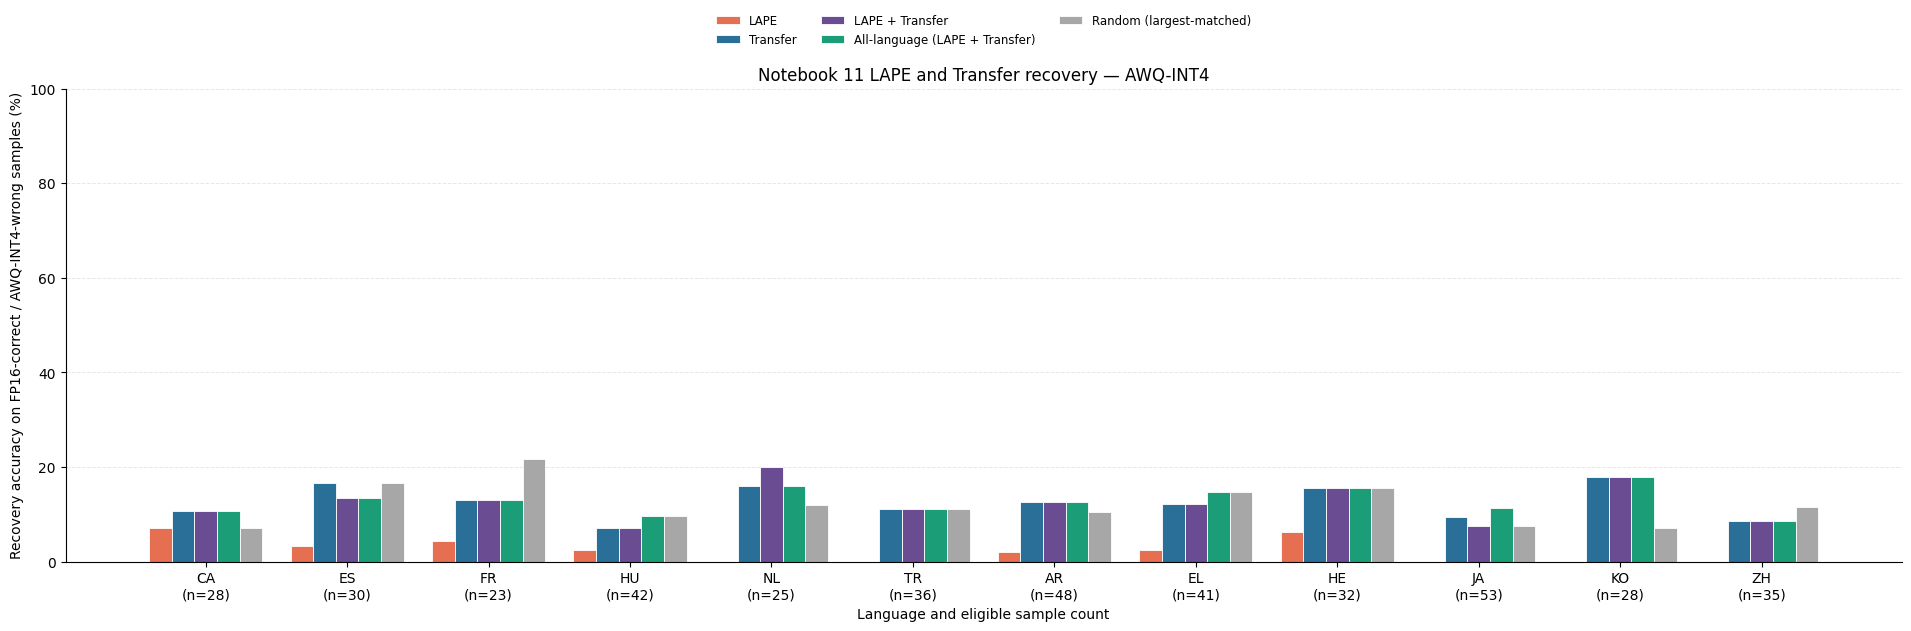

In [11]:
summary_rows = []
paired_rows = []
for language in LAPE_TARGET_LANGUAGES:
    eligible = ELIGIBLE_ROWS[language]
    denominator = len(eligible)
    path = recovery_paths[language]
    if denominator == 0:
        print(language, ': no eligible samples; skipped.')
        continue
    if not path.is_file():
        raise RuntimeError(f'Recovery results not yet available for {language}: {path}')
    frame = pd.read_csv(path, dtype={'sample_id': str}).fillna('')
    expected = {row['sample_id'] for row in eligible}
    if len(frame) != denominator or set(frame['sample_id']) != expected:
        raise RuntimeError(f'Incomplete recovery results for {language}: '
                           f'{len(frame)} / {denominator}')
    if not frame['selection_signature'].eq(signatures[language]).all():
        raise RuntimeError(f'Wrong selection signature in {path}')
    for condition in RECOVERY_CONDITION_NAMES:
        recovered = int(frame[f'{condition}_correct'].map(saved_bool).sum())
        summary_rows.append({'language': language, 'condition': condition,
                             'eligible_samples': denominator,
                             'recovered_samples': recovered,
                             'recovery_rate': recovered / denominator})
    for row in frame.to_dict('records'):
        paired_rows.append({
            'language': language, 'sample_id': row['sample_id'],
            'lape_correct': saved_bool(row['lape_correct']),
            'transfer_correct': saved_bool(row['transfer_correct']),
            'joint_correct': saved_bool(row['lape_plus_transfer_correct']),
            'all_language_correct': saved_bool(row['all_language_lape_plus_transfer_correct']),
            'random_correct': saved_bool(row['random_largest_matched_correct']),
        })
summary_df = pd.DataFrame(summary_rows)
paired_df = pd.DataFrame(paired_rows)
summary_df.to_csv(LAPE_JOINT_OUTPUT_DIR / 'recovery_rates_eligible_only.csv',
                  index=False, encoding='utf-8-sig')
paired_df.to_csv(LAPE_JOINT_OUTPUT_DIR / 'paired_correctness_eligible_only.csv',
                 index=False, encoding='utf-8-sig')
plot_labels = {
    'lape': 'LAPE',
    'transfer': 'Transfer',
    'lape_plus_transfer': 'LAPE + Transfer',
    'all_language_lape_plus_transfer': 'All-language (LAPE + Transfer)',
    'random_largest_matched': 'Random (largest-matched)',
}
recovery_wide = (summary_df.pivot(index='language', columns='condition', values='recovery_rate')
                 .reindex(index=LAPE_TARGET_LANGUAGES, columns=RECOVERY_CONDITION_NAMES))
display((100 * recovery_wide).rename(columns=plot_labels))
if not paired_df.empty:
    comparison_rows = []
    for language, subset in paired_df.groupby('language'):
        comparison_rows.append({
            'language': language,
            'joint_minus_transfer_pp': 100 * (subset['joint_correct'].mean() - subset['transfer_correct'].mean()),
            'all_language_minus_random_pp': 100 * (subset['all_language_correct'].mean() - subset['random_correct'].mean()),
            'joint_only_rescues_vs_transfer': int((subset['joint_correct'] & ~subset['transfer_correct']).sum()),
            'transfer_only_rescues_vs_joint': int((subset['transfer_correct'] & ~subset['joint_correct']).sum()),
        })
    display(pd.DataFrame(comparison_rows).set_index('language'))

if not recovery_wide.empty:
    x = np.arange(len(LAPE_TARGET_LANGUAGES))
    bar_width = 0.16
    colors = ['#E76F51', '#2A6F97', '#6A4C93', '#1B9E77', '#A7A7A7']
    fig, ax = plt.subplots(figsize=(19, 6.2), constrained_layout=True)
    for index, condition in enumerate(RECOVERY_CONDITION_NAMES):
        offset = (index - (len(RECOVERY_CONDITION_NAMES) - 1) / 2) * bar_width
        values = 100 * recovery_wide[condition].to_numpy(dtype=float)
        ax.bar(x + offset, values, width=bar_width,
               label=plot_labels[condition], color=colors[index],
               edgecolor='white', linewidth=0.6)
    n_by_language = {language: len(ELIGIBLE_ROWS[language])
                     for language in LAPE_TARGET_LANGUAGES}
    ax.set_xticks(x)
    ax.set_xticklabels([f'{language.upper()}\n(n={n_by_language[language]})'
                        for language in LAPE_TARGET_LANGUAGES])
    ax.set_ylabel('Recovery accuracy on FP16-correct / AWQ-INT4-wrong samples (%)')
    ax.set_xlabel('Language and eligible sample count')
    ax.set_title(f'Notebook 11 LAPE and Transfer recovery — {QUANT_MODEL_NAME}')
    ax.set_ylim(0, 100)
    ax.grid(axis='y', linestyle='--', linewidth=0.7, alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.18),
              ncol=3, frameon=False, fontsize=8.5)
    chart_path = LAPE_JOINT_OUTPUT_DIR / 'five_condition_recovery_eligible_only'
    fig.savefig(chart_path.with_suffix('.png'), dpi=300, bbox_inches='tight')
    fig.savefig(chart_path.with_suffix('.pdf'), bbox_inches='tight')
    plt.show()
